# Week 11: Assignment 4 — Logistic Regression (Age & Salary → Car Purchase)
**Course:** INFO 4670 — Fengjiao Tu  
**Goal:** Train and evaluate a logistic regression model that predicts whether a customer purchases a car using age and salary.

## I. Assignment Objective
Logistic regression estimates the probability that an observation belongs to a class. It combines the input features linearly, passes the resulting score through the logistic (sigmoid) function, and returns a probability between 0 and 1. A decision threshold (0.50 here) turns that probability into a class label: probabilities at least 0.50 predict a purchase (1), and smaller probabilities predict no purchase (0).

This is appropriate because `Purchased` is a binary outcome. Logistic regression is a supervised classification model that is simple to interpret, produces probabilities, and can draw a linear decision boundary. Age and salary are scaled before fitting so their different units do not dominate optimization.

## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [1]:
# Step 1: Import libraries and load the CSV
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Read the provided CSV from the notebook's working directory.
data = pd.read_csv("car_purchase_data.csv")
print("Dataset shape:", data.shape)
print("Columns:", data.columns.tolist())
print("\nPreview:")
print(data.head())
print("\nTarget counts:")
print(data["Purchased"].value_counts().sort_index())

Dataset shape: (400, 5)
Columns: ['User ID', 'Gender', 'Age', 'Salary', 'Purchased']

Preview:
    User ID  Gender  Age  Salary  Purchased
0  15624510    Male   19   19000          0
1  15810944    Male   35   20000          0
2  15668575  Female   26   43000          0
3  15603246  Female   27   57000          0
4  15804002    Male   19   76000          0

Target counts:
Purchased
0    257
1    143
Name: count, dtype: int64


### Step 2: Split features and target

In [2]:
# Step 2: Use the two features named in the assignment: Age and Salary.
# User ID is an identifier, and Gender is outside this notebook's stated two-feature objective.
X = data[["Age", "Salary"]]
y = data["Purchased"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Feature names:", X.columns.tolist())

Feature shape: (400, 2)
Target shape: (400,)
Feature names: ['Age', 'Salary']


### Step 3: Train/Test Split

In [3]:
# Step 3: Hold out 20% for testing using a fixed seed so the result is reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=0
)
print("Training examples:", len(X_train))
print("Test examples:", len(X_test))
print("Purchase rate (train):", round(y_train.mean(), 3))
print("Purchase rate (test):", round(y_test.mean(), 3))

Training examples: 320
Test examples: 80
Purchase rate (train): 0.378
Purchase rate (test): 0.275


### Step 4: Feature Scaling

In [4]:
# Step 4: Fit the scaler on training data only to prevent test-data leakage.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)
print("Training feature means after scaling:", X_train_scaled.mean(axis=0).round(3))

Scaled training shape: (320, 2)
Scaled test shape: (80, 2)
Training feature means after scaling: [0. 0.]


### Step 5: Train Logistic Regression Model

In [5]:
# Step 5: Train logistic regression on the scaled training data.
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train_scaled, y_train)
print("Model trained.")
print("Scaled-feature coefficients:", model.coef_[0].round(3))
print("Intercept:", round(float(model.intercept_[0]), 3))

Model trained.
Scaled-feature coefficients: [2.003 1.081]
Intercept: -0.871


### Step 6: Predict and Evaluate

In [6]:
# Step 6: Predict classes and purchase probabilities; evaluate on the held-out test set.
y_pred = model.predict(X_test_scaled)
purchase_probability = model.predict_proba(X_test_scaled)[:, 1]
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print(f"Accuracy: {accuracy:.3f} ({accuracy:.1%})")
print("\nConfusion matrix (rows = actual, columns = predicted; labels [0, 1]):")
print(cm)
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No purchase (0)", "Purchase (1)"], zero_division=0))
print("\nFirst five predicted purchase probabilities:")
print(np.round(purchase_probability[:5], 3))
print("\nThreshold used: 0.50; probability >= 0.50 predicts purchase (1).")

Accuracy: 0.925 (92.5%)

Confusion matrix (rows = actual, columns = predicted; labels [0, 1]):
[[57  1]
 [ 5 17]]

Classification report:
                 precision    recall  f1-score   support

No purchase (0)       0.92      0.98      0.95        58
   Purchase (1)       0.94      0.77      0.85        22

       accuracy                           0.93        80
      macro avg       0.93      0.88      0.90        80
   weighted avg       0.93      0.93      0.92        80


First five predicted purchase probabilities:
[0.126 0.177 0.208 0.101 0.107]

Threshold used: 0.50; probability >= 0.50 predicts purchase (1).


### Step 7: Visualization of Decision Regions

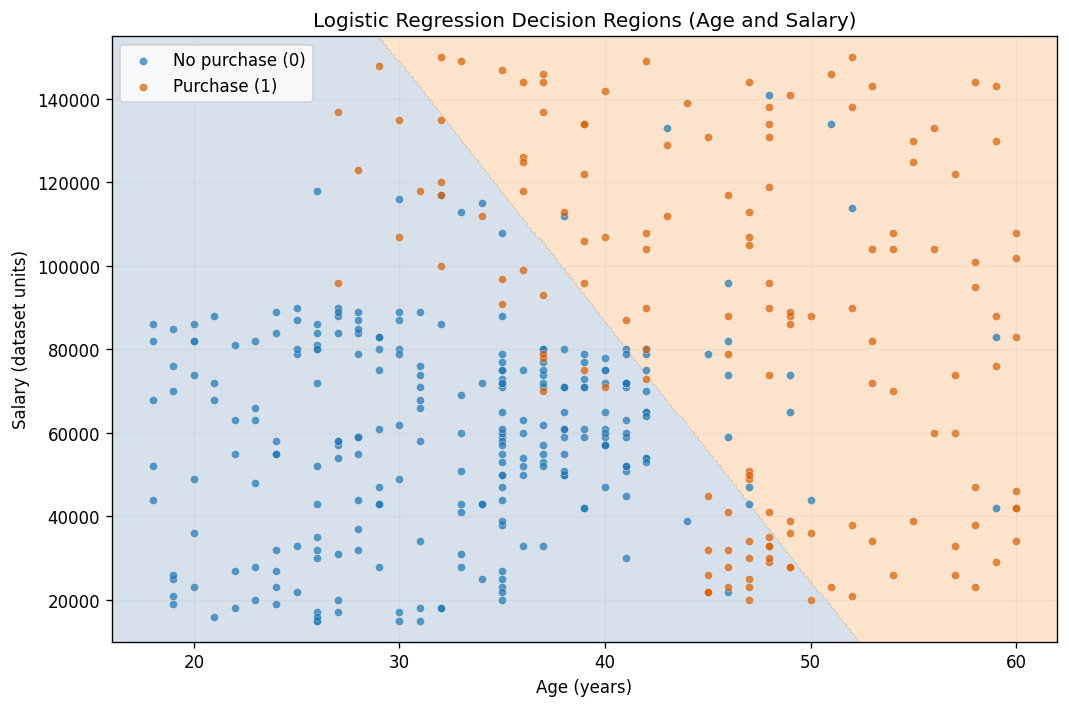

In [7]:
# Step 7: Plot the model's decision regions in the original Age / Salary units.
# The model operates on scaled inputs, so every mesh point is transformed with the fitted scaler.
age_min, age_max = X["Age"].min() - 2, X["Age"].max() + 2
salary_min, salary_max = X["Salary"].min() - 5000, X["Salary"].max() + 5000
age_grid, salary_grid = np.meshgrid(
    np.linspace(age_min, age_max, 250),
    np.linspace(salary_min, salary_max, 250)
)
mesh = pd.DataFrame({"Age": age_grid.ravel(), "Salary": salary_grid.ravel()})
mesh_scaled = scaler.transform(mesh)
regions = model.predict(mesh_scaled).reshape(age_grid.shape)

plt.figure(figsize=(9, 6))
plt.contourf(age_grid, salary_grid, regions, levels=[-0.5, 0.5, 1.5], alpha=0.22, colors=["#4C78A8", "#F58518"])
for label, color, name in [(0, "#1f77b4", "No purchase (0)"), (1, "#d95f02", "Purchase (1)")]:
    mask = (y == label)
    plt.scatter(X.loc[mask, "Age"], X.loc[mask, "Salary"], c=color, label=name, s=24, alpha=0.72, edgecolors="white", linewidths=0.25)
plt.xlabel("Age (years)")
plt.ylabel("Salary (dataset units)")
plt.title("Logistic Regression Decision Regions (Age and Salary)")
plt.legend()
plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()

## IV. Reflection Questions 
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


### Reflection
1. **Why can probabilities be used for classification?** Logistic regression estimates the probability of class 1. With the 0.50 cutoff used here, a probability of at least 0.50 is labeled “purchase” (1), while a lower probability is labeled “no purchase” (0). The cutoff can be adjusted when the costs of false positives and false negatives differ.

2. **Which customers are more likely to purchase?** The fitted model estimates purchase likelihood from age and salary together. On the held-out test set, accuracy was 92.5% (74 of 80 predictions correct). The fitted age coefficient (2.003) and salary coefficient (1.081) indicate that, holding the other scaled feature constant, larger values are associated with higher estimated purchase odds. The pattern is probabilistic; it does not mean every older or higher-salary customer will purchase.

3. **What might cause low accuracy?** Age and salary may not capture the full reasons people buy cars; purchase decisions may also depend on existing vehicle ownership, household needs, credit access, location, and preferences. A linear decision boundary may not fit nonlinear patterns. The finite test sample and the chosen 0.50 threshold can also affect measured accuracy.

4. **How could accuracy be improved?** Add relevant predictors such as employment status, household size, vehicle ownership, and purchase budget, provided they are available and appropriate. Compare stratified cross-validation, regularization settings, and models that capture nonlinear relationships; inspect precision, recall, and the confusion matrix as well as accuracy. Any feature selection and tuning should be done using training data only, with final performance measured on untouched test data.